# Phase 1 Analysis: Causal VAE Training
Set `RUN_DIR` below and run all cells.

In [1]:
# ── CONFIG ──────────────────────────────────────────────────────────────────
import os, sys
REPO = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, REPO)

RUN_DIR        = REPO                              # folder with checkpoints/ and logs/
CKPT_PATH      = os.path.join(RUN_DIR, 'checkpoints/phase1_best.pt')
LOG_CSV        = os.path.join(RUN_DIR, 'logs/phase1_training.csv')
CONFIG_PATH    = os.path.join(REPO, 'configs/default.yaml')
N_DAG_SAMPLES  = 32        # bootstrapped DAG samples for intervention analysis
DEVICE         = 'cuda'    # or 'cpu'

In [2]:
import numpy as np, pandas as pd, torch, yaml, scipy.sparse
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
from tqdm.auto import tqdm

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f)

device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [3]:
# ── LOAD DATA ───────────────────────────────────────────────────────────────
from data.load_norman import load_norman
data_dict = load_norman(path=config['data']['norman_path'], n_hvg=config['data']['n_hvg'])

adata      = data_dict['adata']
gene_names = data_dict['gene_names']
n_genes    = len(gene_names)
control_idx   = data_dict['control_idx']
single_perts  = data_dict['single_perts']
combo_perts   = data_dict['combo_perts']

X = adata.X.toarray().astype(np.float32) if scipy.sparse.issparse(adata.X) else np.array(adata.X, dtype=np.float32)
X_ctrl = X[control_idx]
ctrl_mean = X_ctrl.mean(axis=0)
gene_to_idx = {g: i for i, g in enumerate(gene_names)}

print(f'Genes: {n_genes}, Control cells: {len(control_idx)}, '
      f'Single perts: {len(single_perts)}, Combo perts: {len(combo_perts)}')

Loading Norman dataset from MTX format...
  Loaded 111668 barcodes
  Loaded 33694 genes
  Loading MTX matrix (this may take a moment)...
  Matrix shape (cells x genes): (111668, 33694)
  Cell identities shape: (111445, 8)
  Columns: ['cell_barcode', 'guide_identity', 'read_count', 'UMI_count', 'coverage', 'gemgroup', 'good_coverage', 'number_of_cells']


/home/sgoudarzi/miniconda/lib/python3.13/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/sgoudarzi/CausalBioRL/data/load_norman.py:122: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  good_mask = adata.obs['good_coverage'].fillna(False).astype(bool)


  AnnData shape: (111668, 33694)


/home/sgoudarzi/miniconda/lib/python3.13/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


  After good_coverage filter: 104507 cells
  Parsing guide identities...
  Preprocessing (HVG selection, normalization, PCA)...
  After preprocessing: (104507, 2000)
  Control cells: 11183
  Single perturbations: 105 genes
  Combo perturbations: 131 combos
  Computing differential expression for single perturbations...
  Computing differential expression for combo perturbations...
Genes: 2000, Control cells: 11183, Single perts: 105, Combo perts: 131


In [4]:
# ── LOAD MODEL ──────────────────────────────────────────────────────────────
from models.causal_vae import CausalVAE

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only = False)
cfg_m = config['model']
model = CausalVAE(
    n_genes=n_genes, latent_dim=cfg_m['latent_dim'],
    tau_init=cfg_m['tau_min'], n_dag_samples=cfg_m['n_dag_samples'],
    dagma_s=cfg_m['dagma_s'],
).to(device)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
print(f"Loaded checkpoint from epoch {ckpt['epoch']}, loss={ckpt['loss']:.4f}")

Loaded checkpoint from epoch 21, loss=0.4417


---
## 1. Training Loss Curves

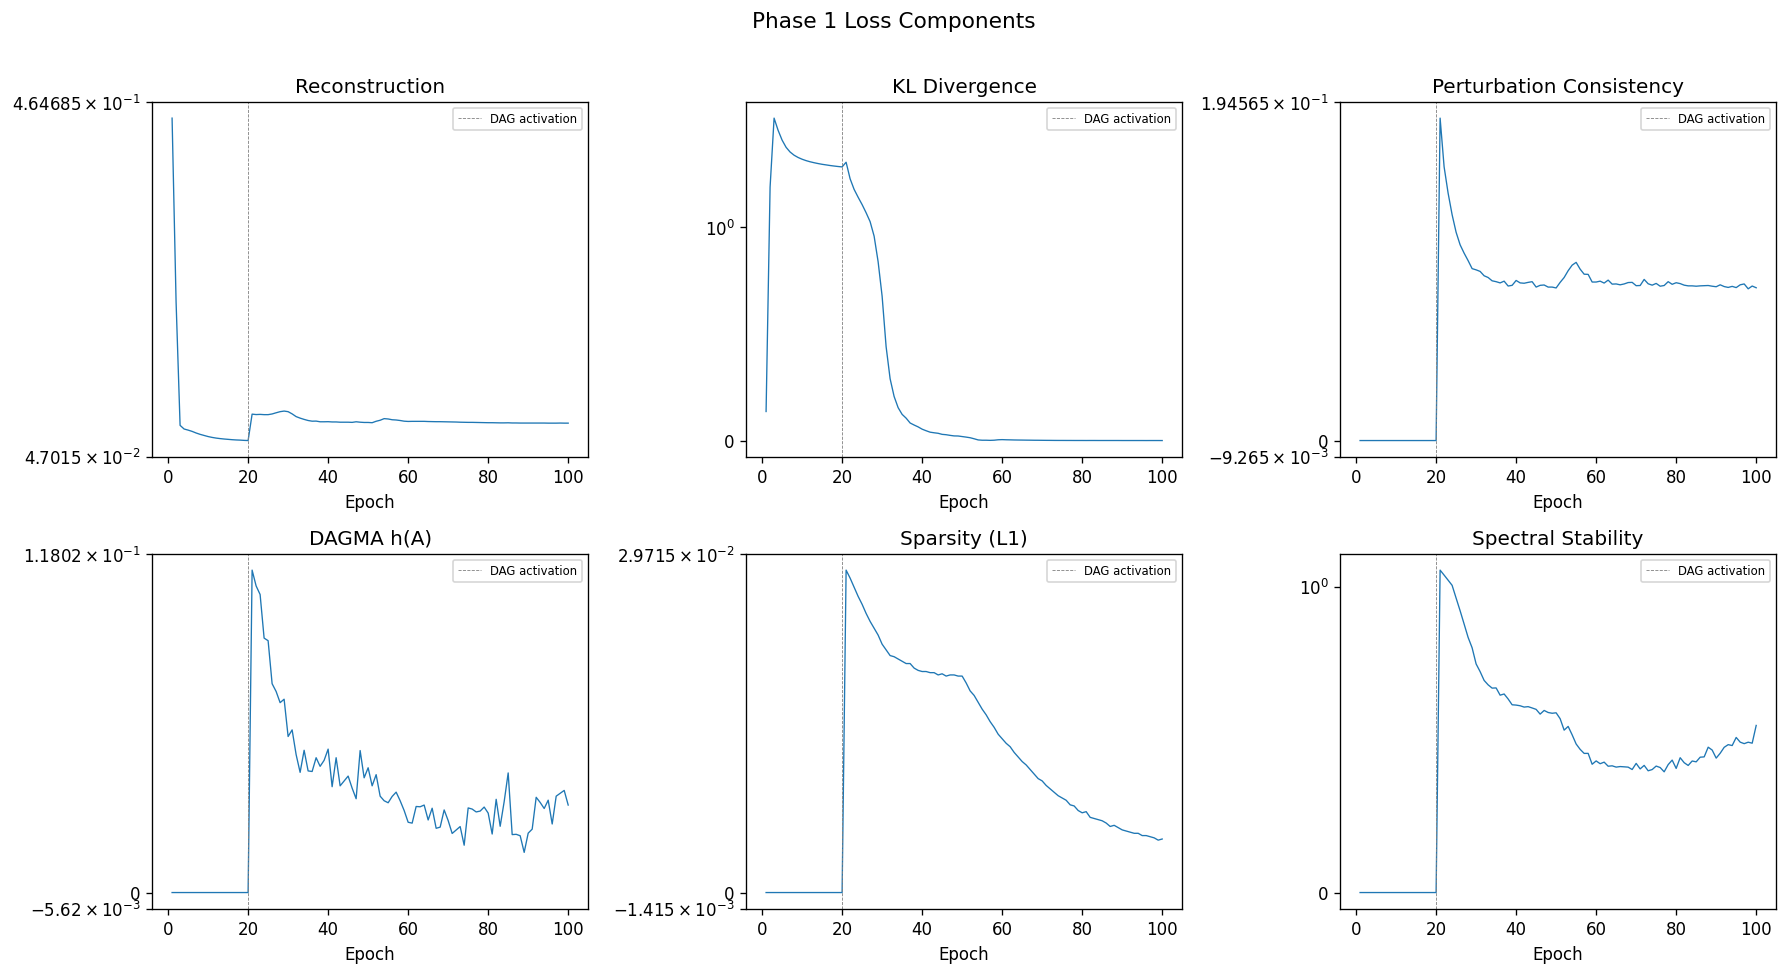

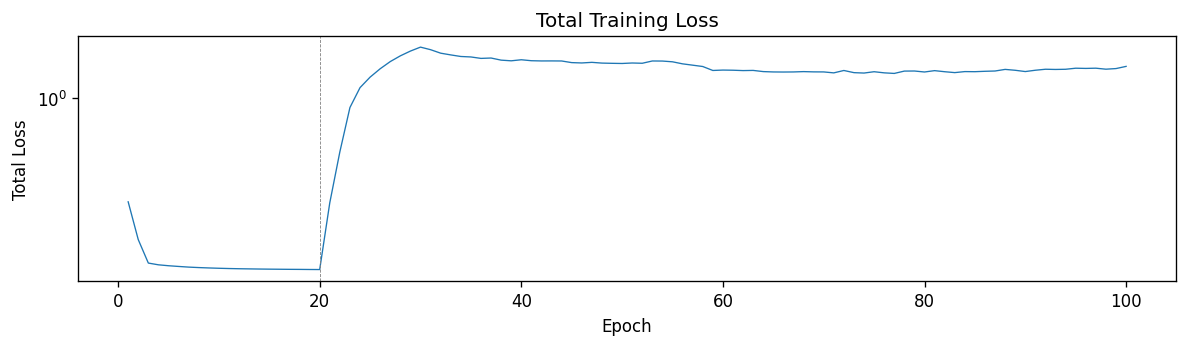

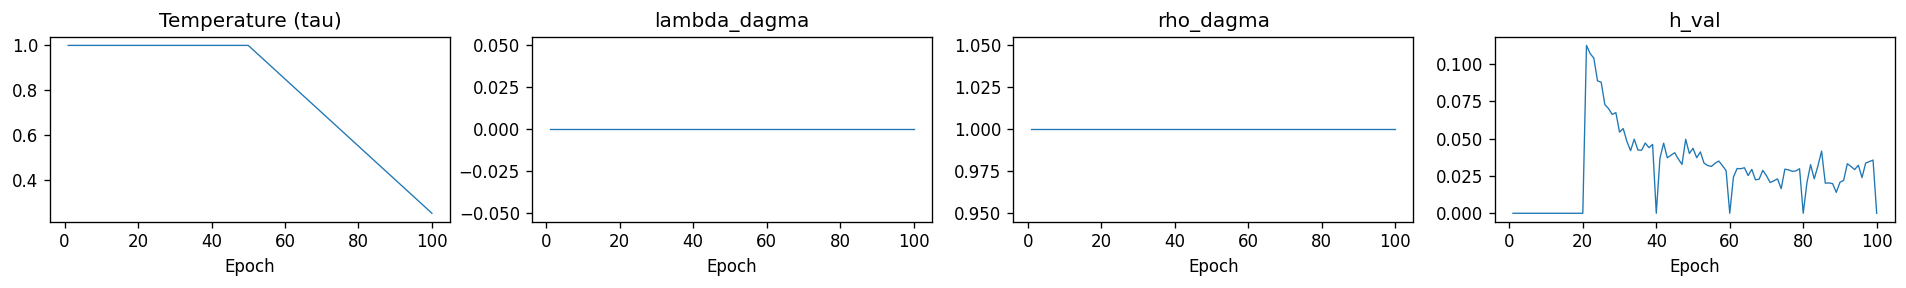

In [5]:
df = pd.read_csv(LOG_CSV)

# main losses
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
panels = [
    ('recon',     'Reconstruction'),
    ('kl',        'KL Divergence'),
    ('pert',      'Perturbation Consistency'),
    ('dag_h',     'DAGMA h(A)'),
    ('sparse',    'Sparsity (L1)'),
    ('spectral',  'Spectral Stability'),
]
for ax, (col, title) in zip(axes.flat, panels):
    if col in df.columns:
        ax.plot(df['epoch'], df[col], lw=0.8)
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.set_yscale('symlog', linthresh=1)
        ax.axvline(x=20, color='grey', ls='--', lw=0.5, label='DAG activation')
        ax.legend(fontsize=7)
plt.suptitle('Phase 1 Loss Components', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# total loss
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df['epoch'], df['total_loss'], lw=0.8)
ax.set_yscale('symlog', linthresh=1)
ax.set(xlabel='Epoch', ylabel='Total Loss', title='Total Training Loss')
ax.axvline(x=20, color='grey', ls='--', lw=0.5)
plt.tight_layout(); plt.show()

# schedule: lr, tau, beta, rho
fig, axes = plt.subplots(1, 4, figsize=(16, 2.5))
for ax, col, title in zip(axes, ['tau','lambda_dagma','rho','h_val'],
                                  ['Temperature (tau)','lambda_dagma','rho_dagma','h_val']):
    if col in df.columns:
        ax.plot(df['epoch'], df[col], lw=0.8)
        ax.set(xlabel='Epoch', title=title)
plt.tight_layout(); plt.show()

---
## 2. DAG Weights & Structure

In [6]:
with torch.no_grad():
    edge_probs = model.dag.get_edge_probs().cpu().numpy()   # [d, d]
    theta      = model.dag.theta.cpu().numpy()
    D          = model.decoder.D.detach().cpu().numpy()      # [n_genes, d]

A_hard = (edge_probs > 0.5).astype(float)
n_edges = int(A_hard.sum())

# DAGMA constraint on hard graph
with torch.no_grad():
    h_hard = model.dag.dagma_constraint(torch.tensor(A_hard, dtype=torch.float32, device=device)).item()

print(f'Edges (p>0.5): {n_edges}')
print(f'Mean edge prob: {edge_probs.mean():.4f}, Max: {edge_probs.max():.4f}')
print(f'Avg in-degree: {A_hard.sum(0).mean():.1f}, Avg out-degree: {A_hard.sum(1).mean():.1f}')
print(f'DAGMA h(A_hard): {h_hard:.6f} (0 = perfect DAG)')

Edges (p>0.5): 0
Mean edge prob: 0.0071, Max: 0.0434
Avg in-degree: 0.0, Avg out-degree: 0.0
DAGMA h(A_hard): 0.000000 (0 = perfect DAG)


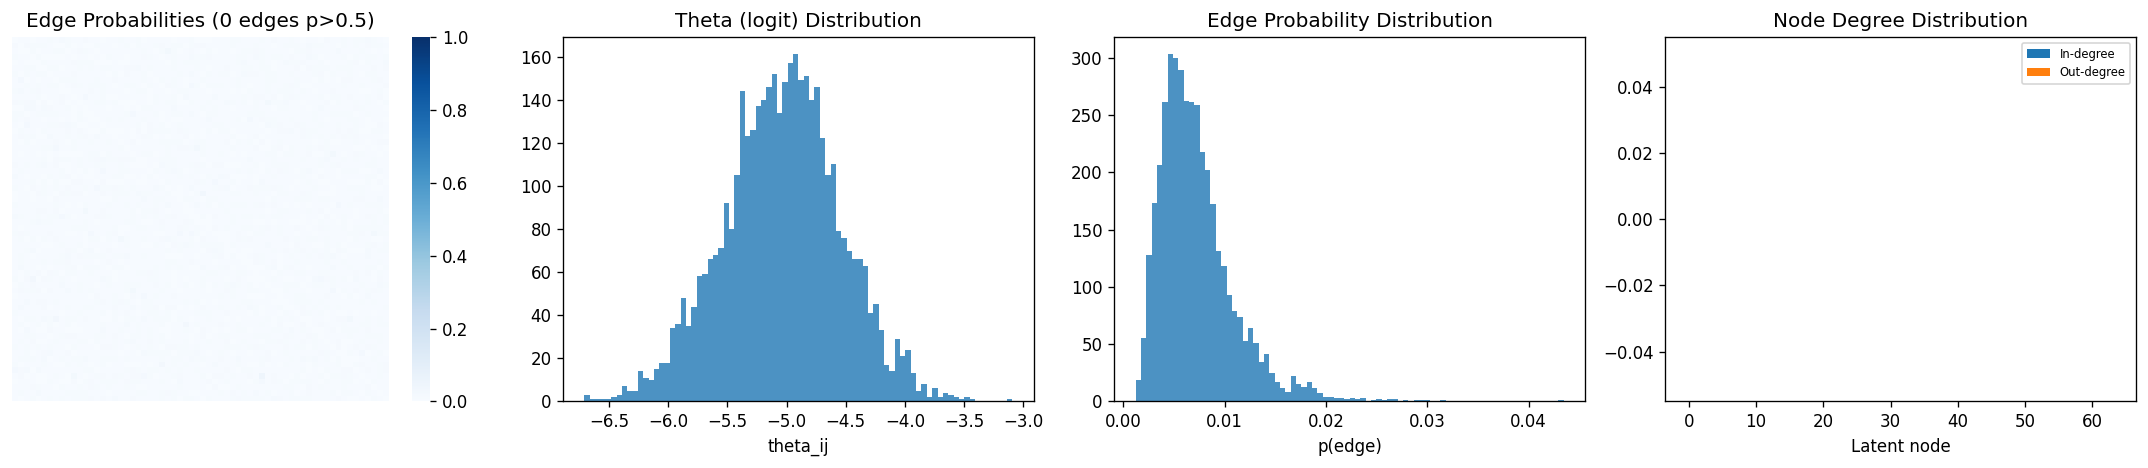

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Edge probability heatmap
sns.heatmap(edge_probs, ax=axes[0], cmap='Blues', vmin=0, vmax=1,
            xticklabels=False, yticklabels=False)
axes[0].set_title(f'Edge Probabilities ({n_edges} edges p>0.5)')

# Theta distribution
axes[1].hist(theta.ravel(), bins=80, edgecolor='none', alpha=0.8)
axes[1].set_title('Theta (logit) Distribution')
axes[1].set_xlabel('theta_ij')

# Edge prob distribution (non-diagonal)
mask = ~np.eye(edge_probs.shape[0], dtype=bool)
axes[2].hist(edge_probs[mask], bins=80, edgecolor='none', alpha=0.8)
axes[2].set_title('Edge Probability Distribution')
axes[2].set_xlabel('p(edge)')

# Degree distribution
in_deg = A_hard.sum(axis=0)
out_deg = A_hard.sum(axis=1)
axes[3].bar(np.arange(len(in_deg))-0.15, in_deg, width=0.3, label='In-degree')
axes[3].bar(np.arange(len(out_deg))+0.15, out_deg, width=0.3, label='Out-degree')
axes[3].set_title('Node Degree Distribution')
axes[3].set_xlabel('Latent node'); axes[3].legend(fontsize=7)

plt.tight_layout(); plt.show()

In [8]:
# Top genes per latent program
d = D.shape[1]
print('Top 5 genes per latent program (first 15):')
for i in range(min(15, d)):
    loadings = np.abs(D[:, i])
    top5 = np.argsort(loadings)[::-1][:5]
    genes_str = ', '.join(f'{gene_names[j]}({loadings[j]:.2f})' for j in top5)
    print(f'  Program {i:2d}: {genes_str}')

Top 5 genes per latent program (first 15):
  Program  0: CD68(0.19), EGR1(0.18), NEAT1(0.18), HBZ(0.18), NGFR(0.18)
  Program  1: DDIT3(0.20), SGTB(0.19), KLK10(0.16), BUB1B(0.16), BIRC5(0.16)
  Program  2: HBZ(0.44), HBG2(0.40), HIST1H4C(0.30), HBG1(0.25), APOE(0.24)
  Program  3: SESN2(0.16), TBX1(0.16), KISS1(0.16), LINC00202-1(0.15), TRGC1(0.15)
  Program  4: HBZ(0.39), HBG2(0.33), UBC(0.18), GYPB(0.18), PRSS57(0.17)
  Program  5: LINC01140(0.19), A4GALT(0.17), TMEM176B(0.17), TUBB4B(0.17), FGFR3(0.17)
  Program  6: HBZ(0.39), HBG2(0.26), HBG1(0.22), GYPB(0.18), CD47(0.18)
  Program  7: SPC24(0.16), CREBRF(0.15), HIST1H4C(0.15), MCM10(0.14), LINC01426(0.14)
  Program  8: HBZ(0.20), TF(0.17), CLC(0.16), SOCS1(0.16), ACRBP(0.16)
  Program  9: LST1(0.25), FEN1(0.18), C12orf45(0.18), CDKN1C(0.17), GMFG(0.17)
  Program 10: OR2B6(0.19), NUP37(0.16), SLC6A19(0.16), MGST1(0.16), RP11-44N12.2(0.16)
  Program 11: ALAS2(0.18), MMP9(0.16), SERPINB8(0.15), SCRT1(0.15), LCP2(0.15)
  Program 12: 

---
## 3. Biological Prior Recovery (CollecTRI)

In [ ]:
from utils.bio_priors import load_collectri, get_tf_target_pairs

collectri_net = load_collectri(organism='human')
ct_pairs = get_tf_target_pairs(collectri_net, gene_names)
print(f'CollecTRI pairs overlapping HVGs: {len(ct_pairs)}')

# Gene-space GRN: G = D @ A @ D^T
# Use soft edge probabilities (not hard threshold) — these capture graded evidence
with torch.no_grad():
    A_prob = model.dag.get_edge_probs()
    G_feat = model.decoder.project_dag_to_genes(A_prob).cpu().numpy()

# Also compute with hard-thresholded A for comparison
with torch.no_grad():
    A_hard_t = torch.tensor(A_hard, dtype=torch.float32, device=device)
    G_feat_hard = model.decoder.project_dag_to_genes(A_hard_t).cpu().numpy()

G_abs = np.abs(G_feat)
G_abs_hard = np.abs(G_feat_hard)

print(f'G_feat (soft) — mean: {G_abs.mean():.6f}, max: {G_abs.max():.4f}, nonzero(>1e-4): {(G_abs > 1e-4).sum()}')
print(f'G_feat (hard) — mean: {G_abs_hard.mean():.6f}, max: {G_abs_hard.max():.4f}, nonzero(>1e-4): {(G_abs_hard > 1e-4).sum()}')

In [ ]:
# Build labels
y_true = np.zeros(n_genes * n_genes, dtype=int)
for tf_i, tgt_i in ct_pairs:
    y_true[tf_i * n_genes + tgt_i] = 1

# Evaluate with soft edge probs (primary)
y_score_soft = G_abs.ravel()
auprc = average_precision_score(y_true, y_score_soft)
auroc = roc_auc_score(y_true, y_score_soft)
baseline_prevalence = y_true.mean()

# Evaluate with hard-thresholded edges
y_score_hard = G_abs_hard.ravel()
if y_score_hard.max() > 0:
    auprc_hard = average_precision_score(y_true, y_score_hard)
    auroc_hard = roc_auc_score(y_true, y_score_hard)
else:
    auprc_hard = baseline_prevalence
    auroc_hard = 0.5

print(f'{"":>18s} {"Soft A":>12s} {"Hard A":>12s}')
print(f'{"AUPRC":>18s} {auprc:>12.4f} {auprc_hard:>12.4f}   (random: {baseline_prevalence:.4f})')
print(f'{"AUROC":>18s} {auroc:>12.4f} {auroc_hard:>12.4f}   (random: 0.5)')

# Top-K precision with soft A
true_set = set(tf_i * n_genes + tgt_i for tf_i, tgt_i in ct_pairs)
sorted_idx = np.argsort(y_score_soft)[::-1]
print(f'\nTop-K precision (soft A):')
for k in [100, 500, 1000, 5000]:
    hits = sum(1 for i in sorted_idx[:k] if i in true_set)
    print(f'  Precision@{k}: {hits/k:.4f} ({hits}/{k} hits)')

if n_edges == 0:
    print(f'\nNote: 0 edges with p>0.5 means the hard-thresholded GRN is all zeros.')
    print(f'The soft edge probabilities still carry graded information (max edge prob: {edge_probs.max():.4f}).')

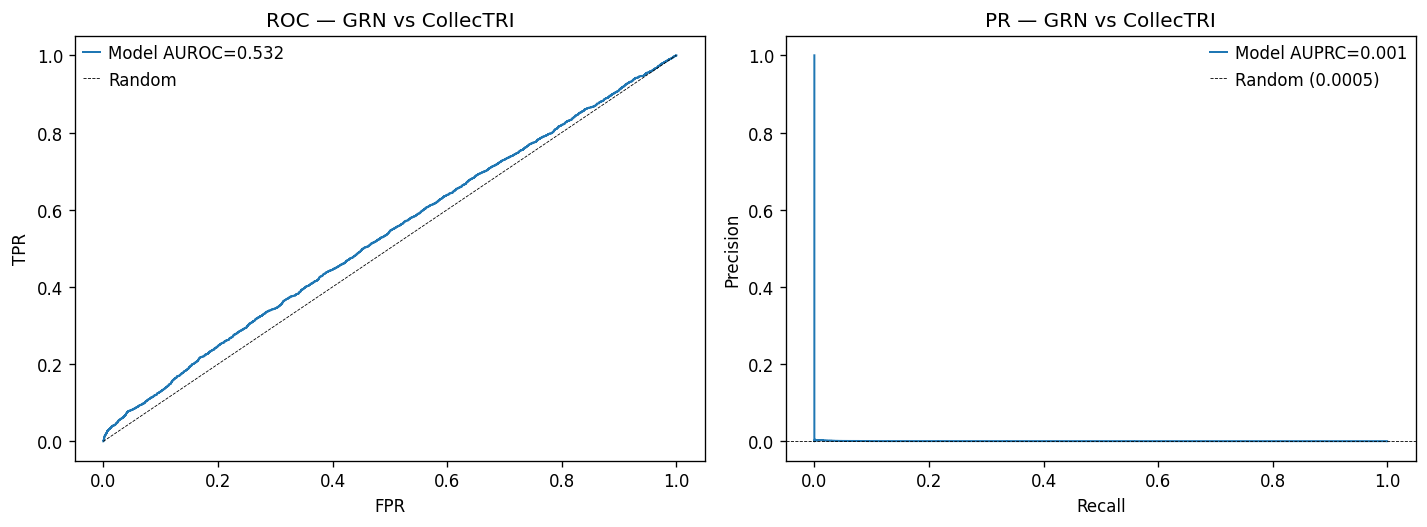

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# AUROC curve
fpr, tpr, _ = roc_curve(y_true, y_score)
axes[0].plot(fpr, tpr, lw=1.2, label=f'Model AUROC={auroc:.3f}')
axes[0].plot([0,1],[0,1],'k--',lw=0.5, label='Random')
axes[0].set(xlabel='FPR', ylabel='TPR', title='ROC — GRN vs CollecTRI')
axes[0].legend()

# PR curve
prec, rec, _ = precision_recall_curve(y_true, y_score)
axes[1].plot(rec, prec, lw=1.2, label=f'Model AUPRC={auprc:.3f}')
axes[1].axhline(y=baseline_prevalence, color='k', ls='--', lw=0.5, label=f'Random ({baseline_prevalence:.4f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title='PR — GRN vs CollecTRI')
axes[1].legend()

plt.tight_layout(); plt.show()

---
## 4. Intervention Analysis (D†-guided Perturbation Prediction)

Uses the v2 perturbation approach:
1. `dz = D†·dx` — project gene-space change to latent space
2. `dε = (I - A^T)·dz` — identify target exogenous variable via DAG
3. `latent_idx = argmax|dε|`, `pert_value = mean(ε_ctrl[:, k]) + dε[k]`
4. Mutilate A at target, set ε, solve SCM → decode → predict

In [ ]:
from utils.metrics import mse_on_degs, pearson_on_degs, direction_accuracy, cosine_similarity

de_single = adata.uns.get('de_single', {})
de_combo  = adata.uns.get('de_combo', {})

# Sample control cells for encoding
rng = np.random.default_rng(42)
ctrl_sample = rng.choice(len(control_idx), min(50, len(control_idx)), replace=False)
x_ctrl_t = torch.tensor(X_ctrl[ctrl_sample], dtype=torch.float32, device=device)

# Pre-encode control cells
with torch.no_grad():
    mu_ctrl, _, eps_ctrl = model.encoder(x_ctrl_t)

In [ ]:
# ── 4a. Single perturbation prediction (D†-guided) ─────────────────────────
single_results = []
single_results_legacy = []  # for comparison with old argmax approach
target_consistency_list = []

for gene, pert_idxs in tqdm(single_perts.items(), desc='Single perts'):
    if gene not in gene_to_idx or len(pert_idxs) < 5:
        continue
    gene_idx = gene_to_idx[gene]
    X_pert_real = X[pert_idxs].mean(axis=0)
    true_de = de_single.get(gene, X_pert_real - ctrl_mean)

    # Get precomputed dx for this gene
    dx_np = de_single.get(gene, None)
    if dx_np is None:
        dx_np = X[pert_idxs].mean(axis=0) - ctrl_mean
    dx_t = torch.tensor(np.asarray(dx_np, dtype=np.float32), device=device)

    with torch.no_grad():
        # D†-based: project dx to latent, then use DAG to find target
        dz = model.compute_dz_from_dx(dx_t)  # [d]
        I_mat = torch.eye(model.latent_dim, device=device)

        A_batch = model.dag.sample_A(n_samples=N_DAG_SAMPLES)
        preds_v2 = []
        latent_targets = []

        for n in range(N_DAG_SAMPLES):
            A = A_batch[n]
            # D†-guided targeting
            d_epsilon = (I_mat - A.T) @ dz  # [d]
            latent_idx = d_epsilon.abs().argmax().item()
            latent_targets.append(latent_idx)
            pert_value = (eps_ctrl[:, latent_idx].mean() + d_epsilon[latent_idx]).item()

            z_post = model.dag.scm_intervene(eps_ctrl, A, latent_idx, pert_value)
            preds_v2.append(model.decoder(z_post).cpu().numpy())

        pred_mean_v2 = np.mean(preds_v2, axis=0).mean(axis=0)

        # Legacy argmax approach for comparison
        latent_idx_legacy = model._get_latent_for_gene(gene_idx)
        x_pert_sample = X[pert_idxs[:min(50, len(pert_idxs))]]
        x_pert_t = torch.tensor(x_pert_sample, dtype=torch.float32, device=device)
        _, _, eps_pert = model.encoder(x_pert_t)
        pv_legacy = eps_pert[:, latent_idx_legacy].mean().item()

        preds_legacy = []
        for n in range(N_DAG_SAMPLES):
            z_post = model.dag.scm_intervene(eps_ctrl, A_batch[n], latent_idx_legacy, pv_legacy)
            preds_legacy.append(model.decoder(z_post).cpu().numpy())
        pred_mean_legacy = np.mean(preds_legacy, axis=0).mean(axis=0)

    # Target consistency: what fraction of unique targets across DAG samples
    n_unique = len(set(latent_targets))
    target_consistency_list.append({
        'gene': gene,
        'n_unique_targets': n_unique,
        'consistency': 1.0 - (n_unique - 1) / max(N_DAG_SAMPLES - 1, 1),
        'primary_target': max(set(latent_targets), key=latent_targets.count),
        'legacy_target': latent_idx_legacy,
        'targets_match': max(set(latent_targets), key=latent_targets.count) == latent_idx_legacy,
    })

    pred_de_v2 = pred_mean_v2 - ctrl_mean
    pred_de_legacy = pred_mean_legacy - ctrl_mean

    single_results.append({
        'gene': gene,
        'pearson_de': pearson_on_degs(pred_de_v2, true_de),
        'direction_acc': direction_accuracy(pred_de_v2, true_de),
        'cosine': cosine_similarity(pred_de_v2, true_de),
        'mse_deg': mse_on_degs(pred_mean_v2, X_pert_real, true_de),
    })
    single_results_legacy.append({
        'gene': gene,
        'pearson_de': pearson_on_degs(pred_de_legacy, true_de),
        'direction_acc': direction_accuracy(pred_de_legacy, true_de),
        'cosine': cosine_similarity(pred_de_legacy, true_de),
        'mse_deg': mse_on_degs(pred_mean_legacy, X_pert_real, true_de),
    })

df_single = pd.DataFrame(single_results)
df_single_legacy = pd.DataFrame(single_results_legacy)
df_targets = pd.DataFrame(target_consistency_list)

print(f'\nSingle perturbation results ({len(df_single)} genes):')
print(f'{"Metric":>18s} {"D† (v2)":>14s} {"argmax (v1)":>14s}')
for m in ['pearson_de', 'direction_acc', 'cosine', 'mse_deg']:
    v2_val = df_single[m].mean()
    v1_val = df_single_legacy[m].mean()
    better = '  ◀' if (v2_val > v1_val if m != 'mse_deg' else v2_val < v1_val) else ''
    print(f'{m:>18s} {v2_val:>6.4f}+/-{df_single[m].std():<6.4f}'
          f' {v1_val:>6.4f}+/-{df_single_legacy[m].std():<6.4f}{better}')

print(f'\nTarget consistency (D† vs legacy):')
print(f'  Mean consistency across DAG samples: {df_targets["consistency"].mean():.3f}')
print(f'  D† primary == legacy argmax: {df_targets["targets_match"].mean():.1%} of genes')
print(f'  Avg unique targets per gene (out of {N_DAG_SAMPLES}): {df_targets["n_unique_targets"].mean():.1f}')

In [ ]:
# ── 4b. Combo perturbation prediction (held-out, D†-guided) ─────────────────
combo_results = []
additive_results = []

for (gene_a, gene_b), pert_idxs in tqdm(combo_perts.items(), desc='Combo perts'):
    if gene_a not in gene_to_idx or gene_b not in gene_to_idx or len(pert_idxs) < 3:
        continue

    ga_idx, gb_idx = gene_to_idx[gene_a], gene_to_idx[gene_b]
    X_real = X[pert_idxs].mean(axis=0)
    key = tuple(sorted([gene_a, gene_b]))
    true_de = de_combo.get(key, X_real - ctrl_mean)

    # Get precomputed dx for each gene from de_single
    dx_a_np = de_single.get(gene_a, None)
    dx_b_np = de_single.get(gene_b, None)

    with torch.no_grad():
        A_batch = model.dag.sample_A(n_samples=N_DAG_SAMPLES)
        I_mat = torch.eye(model.latent_dim, device=device)
        preds_ab = []

        for n in range(N_DAG_SAMPLES):
            A = A_batch[n]

            # D†-based targeting for gene A
            if dx_a_np is not None:
                dx_a_t = torch.tensor(np.asarray(dx_a_np, dtype=np.float32), device=device)
                dz_a = model.compute_dz_from_dx(dx_a_t)
                d_eps_a = (I_mat - A.T) @ dz_a
                la = d_eps_a.abs().argmax().item()
                pv_a = (eps_ctrl[:, la].mean() + d_eps_a[la]).item()
            else:
                la = model._get_latent_for_gene(ga_idx)
                pv_a = 0.0

            # D†-based targeting for gene B
            if dx_b_np is not None:
                dx_b_t = torch.tensor(np.asarray(dx_b_np, dtype=np.float32), device=device)
                dz_b = model.compute_dz_from_dx(dx_b_t)
                d_eps_b = (I_mat - A.T) @ dz_b
                lb = d_eps_b.abs().argmax().item()
                pv_b = (eps_ctrl[:, lb].mean() + d_eps_b[lb]).item()
            else:
                lb = model._get_latent_for_gene(gb_idx)
                pv_b = 0.0

            # Sequential intervention: do(A) then do(B)
            z1 = model.dag.scm_intervene(eps_ctrl, A, la, pv_a)
            z2 = model.dag.scm_intervene(z1, A, lb, pv_b)
            preds_ab.append(model.decoder(z2).cpu().numpy())

        pred_mean = np.mean(preds_ab, axis=0).mean(axis=0)

    pred_de = pred_mean - ctrl_mean

    # Additive baseline: ctrl + de_a + de_b
    eff_a = de_single.get(gene_a, np.zeros(n_genes))
    eff_b = de_single.get(gene_b, np.zeros(n_genes))
    add_pred = ctrl_mean + np.asarray(eff_a) + np.asarray(eff_b)
    add_de = add_pred - ctrl_mean

    combo_results.append({
        'combo': f'{gene_a}+{gene_b}',
        'pearson_de': pearson_on_degs(pred_de, true_de),
        'direction_acc': direction_accuracy(pred_de, true_de),
        'cosine': cosine_similarity(pred_de, true_de),
        'mse_deg': mse_on_degs(pred_mean, X_real, true_de),
    })
    additive_results.append({
        'combo': f'{gene_a}+{gene_b}',
        'pearson_de': pearson_on_degs(add_de, true_de),
        'direction_acc': direction_accuracy(add_de, true_de),
        'cosine': cosine_similarity(add_de, true_de),
        'mse_deg': mse_on_degs(add_pred, X_real, true_de),
    })

df_combo = pd.DataFrame(combo_results)
df_add   = pd.DataFrame(additive_results)

print(f'\nCombo perturbation results ({len(df_combo)} combos):')
print(f'{"Metric":>18s} {"Model (D†)":>14s} {"Additive":>14s}')
for m in ['pearson_de', 'direction_acc', 'cosine', 'mse_deg']:
    if len(df_combo) > 0:
        print(f'{m:>18s} {df_combo[m].mean():>6.4f}+/-{df_combo[m].std():<6.4f}'
              f' {df_add[m].mean():>6.4f}+/-{df_add[m].std():<6.4f}')

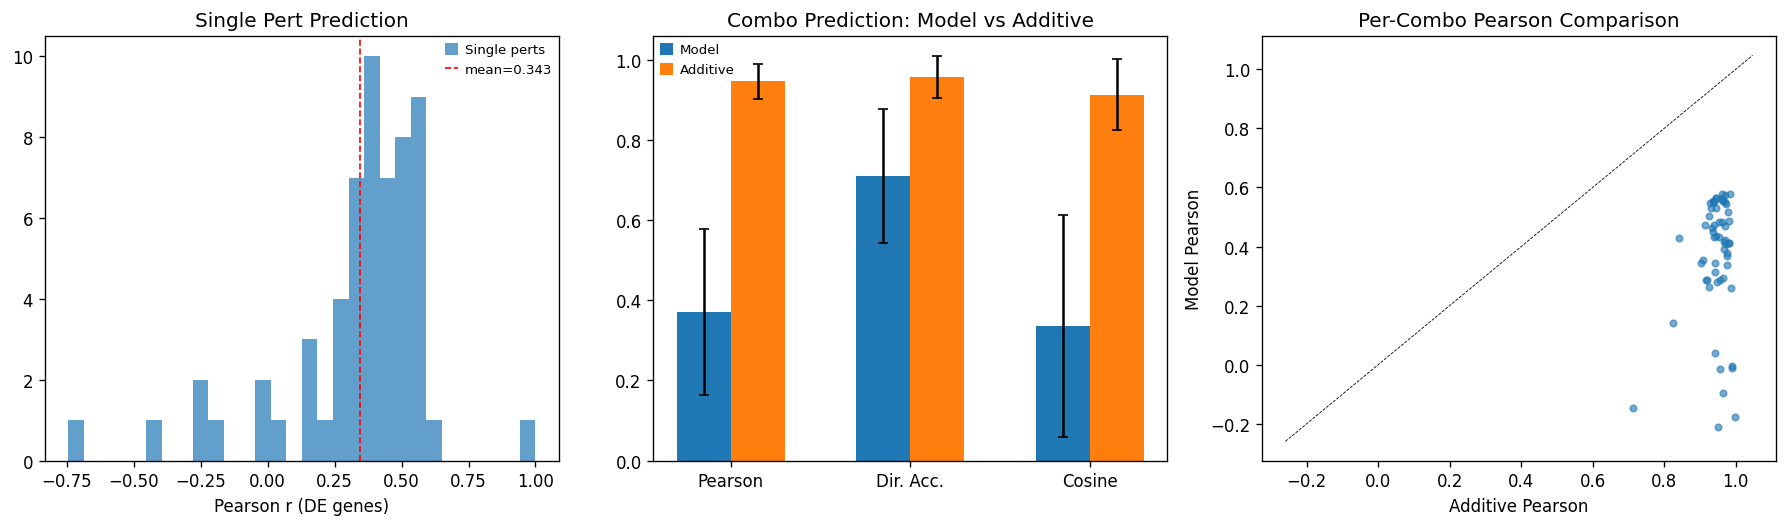

In [15]:
# ── 4c. Summary plots ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Single pert: distribution of pearson
if len(df_single) > 0:
    axes[0].hist(df_single['pearson_de'], bins=30, alpha=0.7, label='Single perts')
    axes[0].axvline(df_single['pearson_de'].mean(), color='red', ls='--', lw=1,
                    label=f'mean={df_single["pearson_de"].mean():.3f}')
    axes[0].set(xlabel='Pearson r (DE genes)', title='Single Pert Prediction')
    axes[0].legend(fontsize=8)

# Combo: model vs additive
if len(df_combo) > 0:
    metrics = ['pearson_de', 'direction_acc', 'cosine']
    x_pos = np.arange(len(metrics))
    model_means = [df_combo[m].mean() for m in metrics]
    add_means   = [df_add[m].mean() for m in metrics]
    model_stds  = [df_combo[m].std() for m in metrics]
    add_stds    = [df_add[m].std() for m in metrics]
    axes[1].bar(x_pos-0.15, model_means, 0.3, yerr=model_stds, label='Model', capsize=3)
    axes[1].bar(x_pos+0.15, add_means, 0.3, yerr=add_stds, label='Additive', capsize=3)
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(['Pearson', 'Dir. Acc.', 'Cosine'])
    axes[1].set_title('Combo Prediction: Model vs Additive')
    axes[1].legend(fontsize=8)

    # Per-combo scatter: model pearson vs additive pearson
    axes[2].scatter(df_add['pearson_de'], df_combo['pearson_de'], s=15, alpha=0.6)
    lims = [min(df_add['pearson_de'].min(), df_combo['pearson_de'].min()) - 0.05,
            max(df_add['pearson_de'].max(), df_combo['pearson_de'].max()) + 0.05]
    axes[2].plot(lims, lims, 'k--', lw=0.5)
    axes[2].set(xlabel='Additive Pearson', ylabel='Model Pearson',
               title='Per-Combo Pearson Comparison')

plt.tight_layout(); plt.show()

In [ ]:
# ── Summary table ───────────────────────────────────────────────────────────
summary = {
    'Checkpoint epoch': ckpt['epoch'],
    'AUPRC (CollecTRI, soft A)': auprc,
    'AUROC (CollecTRI, soft A)': auroc,
    'DAG edges (p>0.5)': n_edges,
    'Mean edge prob': edge_probs.mean(),
    'DAGMA h(A)': h_hard,
}
if len(df_single) > 0:
    summary['Single (D†): Pearson'] = df_single['pearson_de'].mean()
    summary['Single (D†): Dir. Acc'] = df_single['direction_acc'].mean()
    summary['Single (legacy): Pearson'] = df_single_legacy['pearson_de'].mean()
    summary['Single (legacy): Dir. Acc'] = df_single_legacy['direction_acc'].mean()
if len(df_targets) > 0:
    summary['D† target consistency'] = df_targets['consistency'].mean()
    summary['D† == legacy target'] = df_targets['targets_match'].mean()
if len(df_combo) > 0:
    summary['Combo (D†): Pearson'] = df_combo['pearson_de'].mean()
    summary['Combo (D†): Dir. Acc'] = df_combo['direction_acc'].mean()
    summary['Additive baseline: Pearson'] = df_add['pearson_de'].mean()

print('\n=== Phase 1 Summary ===')
for k, v in summary.items():
    if isinstance(v, float):
        print(f'  {k:35s}: {v:.4f}')
    else:
        print(f'  {k:35s}: {v}')

---
## 5. D†-Based Targeting Diagnostics

In [16]:
# ── Summary table ───────────────────────────────────────────────────────────
summary = {
    'AUPRC (CollecTRI)': auprc,
    'AUROC (CollecTRI)': auroc,
    'DAG edges (p>0.5)': n_edges,
    'DAGMA h(A)': h_hard,
}
if len(df_single) > 0:
    summary['Single: Pearson (DE)'] = df_single['pearson_de'].mean()
    summary['Single: Dir. Accuracy'] = df_single['direction_acc'].mean()
if len(df_combo) > 0:
    summary['Combo: Pearson (DE)'] = df_combo['pearson_de'].mean()
    summary['Combo: Dir. Accuracy'] = df_combo['direction_acc'].mean()
    summary['Additive: Pearson (DE)'] = df_add['pearson_de'].mean()

print('\n=== Phase 1 Summary ===')
for k, v in summary.items():
    print(f'  {k:28s}: {v:.4f}' if isinstance(v, float) else f'  {k:28s}: {v}')


=== Phase 1 Summary ===
  AUPRC (CollecTRI)           : 0.0007
  AUROC (CollecTRI)           : 0.5324
  DAG edges (p>0.5)           : 0
  DAGMA h(A)                  : 0.0000
  Single: Pearson (DE)        : 0.3435
  Single: Dir. Accuracy       : 0.7319
  Combo: Pearson (DE)         : 0.3697
  Combo: Dir. Accuracy        : 0.7096
  Additive: Pearson (DE)      : 0.9459
